In [ ]:

%pip -q install qiskit qiskit-machine-learning scikit-learn pandas matplotlib wfdb


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.8 MB/s eta 0:00:00


In [ ]:

import qiskit
import sklearn
import pandas
import matplotlib
import wfdb
import qiskit_machine_learning

print("Qiskit:", qiskit.__version__)
print("Qiskit Machine Learning:", qiskit_machine_learning.__version__)
print("Environment ready!")


Qiskit: 2.5.2
Qiskit Machine Learning: 0.9.1
Environment ready!


In [ ]:

import wfdb
import numpy as np
import pandas as pd
from pathlib import Path

# Small MIT-BIH prototype dataset
TRAIN_RECORDS = ["100", "101", "103", "105", "106", "108", "109", "111"]
TEST_RECORDS  = ["112", "113", "115", "117", "118"]

# MIT-BIH beat annotation symbols
BEAT_SYMBOLS = {
    "N", "L", "R", "e", "j", "A", "a", "J", "S",
    "V", "F", "!", "E", "/", "f", "Q", "?"
}

def load_records(record_ids, split_name):
    rows = []
    for record_id in record_ids:
        print(f"Loading record {record_id}...")
        record = wfdb.rdrecord(record_id, pn_dir="mitdb")
        annotation = wfdb.rdann(record_id, "atr", pn_dir="mitdb")

        # Use the first ECG channel
        signal = record.p_signal[:, 0]
        fs = float(record.fs)

        before = int(0.20 * fs)
        after = int(0.40 * fs)

        for sample, symbol in zip(annotation.sample, annotation.symbol):
            if symbol not in BEAT_SYMBOLS:
                continue

            start, end = sample - before, sample + after
            if start < 0 or end > len(signal):
                continue

            segment = signal[start:end]
            if len(segment) == 0:
                continue

            # Eight numerical ECG morphology features
            features = [
                np.mean(segment),
                np.std(segment),
                np.min(segment),
                np.max(segment),
                np.ptp(segment),
                np.sqrt(np.mean(segment ** 2)),
                np.mean(np.abs(segment)),
                np.mean(np.abs(np.diff(segment)))
            ]

            # Prototype binary labels: N = normal; other beat symbols = abnormal
            label = 0 if symbol == "N" else 1

            rows.append({
                "record": record_id,
                "label": label,
                "beat_symbol": symbol,
                **{f"f{i+1}": value for i, value in enumerate(features)}
            })

    result = pd.DataFrame(rows)
    result["split"] = split_name
    return result

train_df = load_records(TRAIN_RECORDS, "train")
test_df = load_records(TEST_RECORDS, "test")

print("\nDataset loaded!")
print("Training beats:", len(train_df))
print("Testing beats:", len(test_df))
print("\nTraining label counts:\n", train_df["label"].value_counts())
print("\nTesting label counts:\n", test_df["label"].value_counts())

# Save the data so we can reuse it
Path("/content/results").mkdir(exist_ok=True)
train_df.to_csv("/content/results/ecg_train.csv", index=False)
test_df.to_csv("/content/results/ecg_test.csv", index=False)

print("\nSaved ECG datasets to /content/results/")


Loading record 100...
Loading record 101...
Loading record 103...
Loading record 105...
Loading record 106...
Loading record 108...
Loading record 109...
Loading record 111...
Loading record 112...
Loading record 113...
Loading record 115...
Loading record 117...
Loading record 118...

Dataset loaded!
Training beats: 17237
Testing beats: 10095

Training label counts:
 label
0    11951
1     5286
Name: count, dtype: int64

Testing label counts:
 label
0    7809
1    2286
Name: count, dtype: int64

Saved ECG datasets to /content/results/


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

project_folder = "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
os.makedirs(project_folder, exist_ok=True)

for filename in ["ecg_train.csv", "ecg_test.csv", "baseline_results.csv"]:
    source = f"/content/results/{filename}"
    if os.path.exists(source):
        shutil.copy2(source, project_folder)
        print("Saved:", filename)
    else:
        print("Not created yet:", filename)

print("Project folder:", project_folder)



Mounted at /content/drive
Saved: ecg_train.csv
Saved: ecg_test.csv
Not created yet: baseline_results.csv
Project folder: /content/drive/MyDrive/Qiskit_Biomedical_Classifier


In [6]:

import os
from pathlib import Path

print("=== CHECKING COLAB FILES ===")

for folder in ["/content/results",
               "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"]:
    print(f"\n{folder}")
    if os.path.isdir(folder):
        files = list(Path(folder).glob("*"))
        if files:
            for f in files:
                print(f"  FOUND: {f.name} ({f.stat().st_size:,} bytes)")
        else:
            print("  Folder exists but is empty.")
    else:
        print("  Folder not found.")

print("\n=== CHECKING RUNTIME VARIABLES ===")
for name in ["train_df", "test_df", "baseline"]:
    print(f"{name}: {'available' if name in globals() else 'not available'}")


=== CHECKING COLAB FILES ===

/content/results
  FOUND: ecg_test.csv (1,323,881 bytes)
  FOUND: ecg_train.csv (2,291,932 bytes)

/content/drive/MyDrive/Qiskit_Biomedical_Classifier
  FOUND: ecg_train.csv (2,291,932 bytes)
  FOUND: ecg_test.csv (1,323,881 bytes)

=== CHECKING RUNTIME VARIABLES ===
train_df: available
test_df: available
baseline: not available


In [7]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    classification_report, confusion_matrix
)
import pandas as pd
import os

FEATURES = [f"f{i}" for i in range(1, 9)]

X_train = train_df[FEATURES].to_numpy()
y_train = train_df["label"].to_numpy()
X_test = test_df[FEATURES].to_numpy()
y_test = test_df["label"].to_numpy()

print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))
print("Training classes:", pd.Series(y_train).value_counts().to_dict())
print("Testing classes:", pd.Series(y_test).value_counts().to_dict())

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

baseline.fit(X_train, y_train)
predictions = baseline.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
f1 = f1_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)

print("\n=== LOGISTIC REGRESSION BASELINE ===")
print(f"Accuracy: {accuracy:.4f}")
print(f"Abnormal-class F1: {f1:.4f}")
print(f"Abnormal-class recall: {recall:.4f}")
print("\n", classification_report(
    y_test, predictions,
    labels=[0, 1],
    target_names=["Normal", "Abnormal"],
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_test, predictions, labels=[0, 1]))

os.makedirs("/content/results", exist_ok=True)
baseline_results = pd.DataFrame([{
    "model": "Logistic Regression",
    "accuracy": accuracy,
    "abnormal_f1": f1,
    "abnormal_recall": recall
}])
baseline_results.to_csv(
    "/content/results/baseline_results.csv", index=False
)

drive_folder = "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
os.makedirs(drive_folder, exist_ok=True)
baseline_results.to_csv(
    f"{drive_folder}/baseline_results.csv", index=False
)

print("\nBaseline results saved to Google Drive!")


Training samples: 17237
Testing samples: 10095
Training classes: {0: 11951, 1: 5286}
Testing classes: {0: 7809, 1: 2286}

=== LOGISTIC REGRESSION BASELINE ===
Accuracy: 0.7466
Abnormal-class F1: 0.0455
Abnormal-class recall: 0.0267

               precision    recall  f1-score   support

      Normal       0.77      0.96      0.85      7809
    Abnormal       0.15      0.03      0.05      2286

    accuracy                           0.75     10095
   macro avg       0.46      0.49      0.45     10095
weighted avg       0.63      0.75      0.67     10095

Confusion matrix:
[[7476  333]
 [2225   61]]

Baseline results saved to Google Drive!


In [8]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

FEATURES = [f"f{i}" for i in range(1, 9)]
rng = np.random.default_rng(42)

def balanced_sample(df, n_per_class):
    pieces = []
    for label in [0, 1]:
        group = df[df["label"] == label]
        n = min(n_per_class, len(group))
        pieces.append(group.sample(n=n, random_state=42))
    return pd.concat(pieces).sample(frac=1, random_state=42).reset_index(drop=True)

# Keep the initial experiment small
train_small = balanced_sample(train_df, 100)
test_small = balanced_sample(test_df, 40)

# Fit all preprocessing ONLY on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train_small[FEATURES])
X_test_scaled = scaler.transform(test_small[FEATURES])

pca = PCA(n_components=4, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

angle_scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_q = angle_scaler.fit_transform(X_train_pca)
X_test_q = angle_scaler.transform(X_test_pca)

y_train_q = train_small["label"].to_numpy()
y_test_q = test_small["label"].to_numpy()

print("Quantum training set:", X_train_q.shape)
print("Quantum test set:", X_test_q.shape)
print("Training labels:", np.bincount(y_train_q))
print("Test labels:", np.bincount(y_test_q))
print("Explained variance by 4 PCA components:",
      round(pca.explained_variance_ratio_.sum(), 4))
print("Quantum input preparation complete!")


Quantum training set: (200, 4)
Quantum test set: (80, 4)
Training labels: [100 100]
Test labels: [40 40]
Explained variance by 4 PCA components: 0.9805
Quantum input preparation complete!


In [11]:

import qiskit
import qiskit_machine_learning as qml

print("Qiskit version:", qiskit.__version__)
print("Qiskit Machine Learning version:", qml.__version__)

from qiskit_machine_learning.algorithms import VQC
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit_algorithms.optimizers import COBYLA
from qiskit.primitives import StatevectorSampler

print("VQC imports successful!")


Qiskit version: 2.5.2
Qiskit Machine Learning version: 0.9.1
VQC imports successful!


In [12]:

import qiskit
import qiskit_machine_learning
import qiskit_algorithms

from qiskit_algorithms.optimizers import COBYLA
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.algorithms import VQC
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes

print("All imports successful!")
print("Qiskit:", qiskit.__version__)
print("Qiskit Machine Learning:", qiskit_machine_learning.__version__)


All imports successful!
Qiskit: 2.5.2
Qiskit Machine Learning: 0.9.1


In [10]:

%pip -q install qiskit-algorithms


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 5.4 MB/s eta 0:00:00


In [13]:

import numpy as np
import pandas as pd
import os

from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.primitives import StatevectorSampler
from qiskit_algorithms.optimizers import COBYLA
from qiskit_machine_learning.algorithms import VQC
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Four qubits, one per prepared feature
num_qubits = 4

feature_map = ZZFeatureMap(
    feature_dimension=num_qubits,
    reps=1,
    entanglement="linear"
)

ansatz = RealAmplitudes(
    num_qubits=num_qubits,
    reps=1,
    entanglement="linear"
)

circuit = feature_map.compose(ansatz)
print("VQC circuit:")
print(circuit.draw(output="text"))

# Use a local statevector sampler for this first simulation
sampler = StatevectorSampler(seed=42)

vqc = VQC(
    sampler=sampler,
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=30),
    loss="cross_entropy",
    interpret=lambda x: x % 2,
    pass_manager=None
)

print("\nTraining VQC... please wait.")
vqc.fit(X_train_q, y_train_q)
print("VQC training finished!")

pred_q = np.asarray(vqc.predict(X_test_q)).astype(int).ravel()

q_accuracy = accuracy_score(y_test_q, pred_q)
q_f1 = f1_score(y_test_q, pred_q, zero_division=0)
q_recall = recall_score(y_test_q, pred_q, zero_division=0)

print("\n=== 4-QUBIT VQC RESULTS ===")
print(f"Accuracy: {q_accuracy:.4f}")
print(f"Abnormal-class F1: {q_f1:.4f}")
print(f"Abnormal-class recall: {q_recall:.4f}")

os.makedirs("/content/results", exist_ok=True)

quantum_results = pd.DataFrame([{
    "model": "4-qubit VQC",
    "accuracy": q_accuracy,
    "abnormal_f1": q_f1,
    "abnormal_recall": q_recall
}])

quantum_results.to_csv(
    "/content/results/vqc_results.csv", index=False
)

drive_folder = "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
os.makedirs(drive_folder, exist_ok=True)
quantum_results.to_csv(
    f"{drive_folder}/vqc_results.csv", index=False
)

print("\nVQC results saved to Google Drive!")


/tmp/ipykernel_1723/1276845872.py:14: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(
/tmp/ipykernel_1723/1276845872.py:20: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


VQC circuit:
     ┌────────────────────────────────────┐»
q_0: ┤0                                   ├»
     │                                    │»
q_1: ┤1                                   ├»
     │  ZZFeatureMap(x[0],x[1],x[2],x[3]) │»
q_2: ┤2                                   ├»
     │                                    │»
q_3: ┤3                                   ├»
     └────────────────────────────────────┘»
«     ┌──────────────────────────────────────────────────────────┐
«q_0: ┤0                                                         ├
«     │                                                          │
«q_1: ┤1                                                         ├
«     │  RealAmplitudes(θ[0],θ[1],θ[2],θ[3],θ[4],θ[5],θ[6],θ[7]) │
«q_2: ┤2                                                         ├
«     │                                                          │
«q_3: ┤3                                                         ├
«     └───────────────────────────────────────

In [14]:

from qiskit import transpile
from qiskit.transpiler import CouplingMap
import pandas as pd
import os

# Official Processor A topology from the supplied challenge materials
edges_A = [(0, 1), (1, 2), (1, 3), (3, 4)]

coupling_A = CouplingMap(
    couplinglist=edges_A,
    description="Processor A: 5 qubits"
)

compiled_A = transpile(
    circuit,
    coupling_map=coupling_A,
    basis_gates=["rz", "sx", "x", "cx"],
    optimization_level=1,
    seed_transpiler=42
)

metrics_A = {
    "processor": "A",
    "physical_qubits": 5,
    "logical_qubits": circuit.num_qubits,
    "depth": compiled_A.depth(),
    "cx_count": compiled_A.count_ops().get("cx", 0),
    "swap_count": compiled_A.count_ops().get("swap", 0),
    "total_operations": sum(compiled_A.count_ops().values())
}

print("=== PROCESSOR A: COMPILED CIRCUIT ===")
print(compiled_A.draw(output="text"))
print("\n=== RESOURCE METRICS ===")
for key, value in metrics_A.items():
    print(f"{key}: {value}")

os.makedirs("/content/results", exist_ok=True)
pd.DataFrame([metrics_A]).to_csv(
    "/content/results/processor_A_metrics.csv", index=False
)

drive_folder = "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
os.makedirs(drive_folder, exist_ok=True)
pd.DataFrame([metrics_A]).to_csv(
    f"{drive_folder}/processor_A_metrics.csv", index=False
)

print("\nProcessor A metrics saved to Drive!")


=== PROCESSOR A: COMPILED CIRCUIT ===
global phase: π/4 + x[3] + 9π/4 + x[2] + 9π/4 + x[1] + 9π/4 + x[0] + (π - x[0])*(π - x[1]) + 3π/2 + (π - x[1])*(π - x[2]) + 3π/2 + 3π/2 + (π - x[2])*(π - x[3]) + 3π/2 + 3π/2 + 3π/2 + 3π/2 + 3π/2
         ┌─────────┐┌────┐┌─────────┐┌────────────┐     »
q_0 -> 0 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(2*x[0]) ├──■──»
         ├─────────┤├────┤├─────────┤├────────────┤┌─┴─┐»
q_1 -> 1 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(2*x[1]) ├┤ X ├»
         ├─────────┤├────┤├─────────┤├────────────┤└───┘»
q_2 -> 3 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(2*x[2]) ├─────»
         ├─────────┤├────┤├─────────┤├────────────┤     »
q_3 -> 4 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(2*x[3]) ├─────»
         └─────────┘└────┘└─────────┘└────────────┘     »
«                                             ┌────┐»
«q_0 -> 0 ─────────────────────────────────■──┤ √X ├»
«         ┌─────────────────────────────┐┌─┴─┐└────┘»
«q_1 -> 1 ┤ Rz(2*(π - x[0])*(π - x[1])) ├┤ X ├──■───»
«         └──────────────────

In [15]:

edges_B = [
    (0, 1), (1, 2), (1, 6), (2, 3),
    (2, 6), (2, 5), (3, 4), (4, 5),
    (5, 6), (6, 7), (6, 8), (8, 0)
]


In [16]:

from qiskit import transpile
from qiskit.transpiler import CouplingMap
import pandas as pd
import os

coupling_B = CouplingMap(
    couplinglist=edges_B,
    description="Processor B: 9 qubits"
)

compiled_B = transpile(
    circuit,
    coupling_map=coupling_B,
    basis_gates=["rz", "sx", "x", "cx"],
    optimization_level=1,
    seed_transpiler=42
)

metrics_B = {
    "processor": "B",
    "physical_qubits": 9,
    "logical_qubits": circuit.num_qubits,
    "depth": compiled_B.depth(),
    "cx_count": compiled_B.count_ops().get("cx", 0),
    "swap_count": compiled_B.count_ops().get("swap", 0),
    "total_operations": sum(compiled_B.count_ops().values())
}

print("=== PROCESSOR B: COMPILED CIRCUIT ===")
print(compiled_B.draw(output="text"))
print("\n=== RESOURCE METRICS ===")
for key, value in metrics_B.items():
    print(f"{key}: {value}")

# Save Processor B metrics
os.makedirs("/content/results", exist_ok=True)
pd.DataFrame([metrics_B]).to_csv(
    "/content/results/processor_B_metrics.csv", index=False
)

drive_folder = "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
os.makedirs(drive_folder, exist_ok=True)
pd.DataFrame([metrics_B]).to_csv(
    f"{drive_folder}/processor_B_metrics.csv", index=False
)

# Combine Processor A and B metrics
metrics_A["processor"] = "A"
comparison = pd.DataFrame([metrics_A, metrics_B])
comparison.to_csv(
    f"{drive_folder}/processor_comparison.csv", index=False
)

print("\nProcessor B metrics and comparison saved to Drive!")


=== PROCESSOR B: COMPILED CIRCUIT ===
global phase: π/4 + x[3] + 9π/4 + x[2] + 9π/4 + x[1] + 9π/4 + x[0] + (π - x[0])*(π - x[1]) + 3π/2 + (π - x[1])*(π - x[2]) + 3π/2 + 3π/2 + (π - x[2])*(π - x[3]) + 3π/2 + 3π/2 + 3π/2 + 3π/2 + 3π/2
         ┌─────────┐┌────┐┌─────────┐┌────────────┐     »
q_0 -> 0 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(2*x[0]) ├──■──»
         ├─────────┤├────┤├─────────┤├────────────┤┌─┴─┐»
q_1 -> 1 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(2*x[1]) ├┤ X ├»
         ├─────────┤├────┤├─────────┤├────────────┤└───┘»
q_2 -> 2 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(2*x[2]) ├─────»
         ├─────────┤├────┤├─────────┤├────────────┤     »
q_3 -> 3 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├┤ Rz(2*x[3]) ├─────»
         └─────────┘└────┘└─────────┘└────────────┘     »
«                                             ┌────┐»
«q_0 -> 0 ─────────────────────────────────■──┤ √X ├»
«         ┌─────────────────────────────┐┌─┴─┐└────┘»
«q_1 -> 1 ┤ Rz(2*(π - x[0])*(π - x[1])) ├┤ X ├──■───»
«         └──────────────────

=== MODEL PERFORMANCE ===


,Model,Accuracy,Abnormal F1,Abnormal Recall
0,Logistic Regression,0.7466,0.0455,0.0267
1,4-qubit VQC,0.4625,0.3582,0.3000


=== PROCESSOR RESOURCE COMPARISON ===


,Processor,Physical qubits,Logical qubits,Depth,CX gates,SWAP gates,Total operations
0,A,5,4,23,9,0,60
1,B,9,4,23,9,0,60


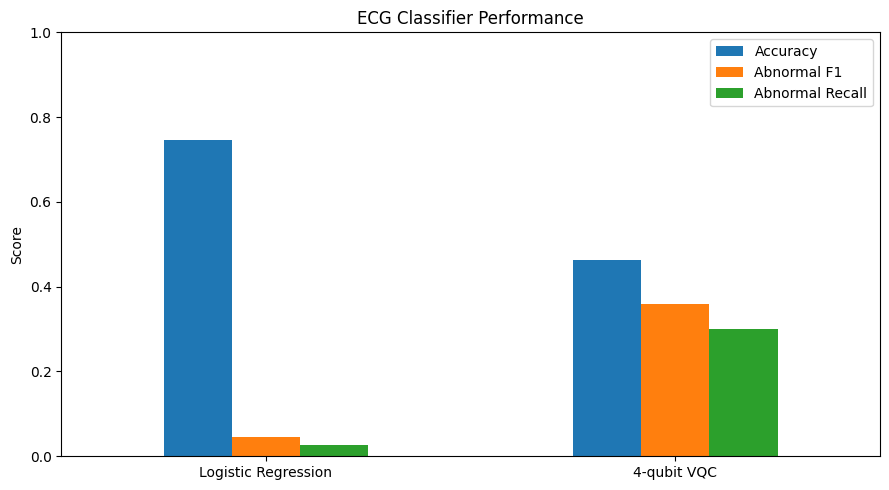

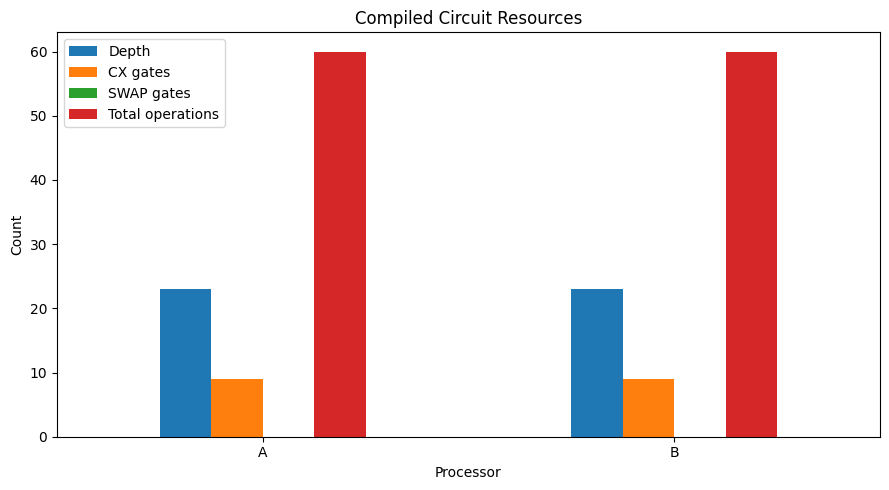

Tables and graphs saved in: /content/drive/MyDrive/Qiskit_Biomedical_Classifier


In [17]:

import os
import pandas as pd
import matplotlib.pyplot as plt

drive_folder = "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
results_folder = "/content/results"
os.makedirs(drive_folder, exist_ok=True)
os.makedirs(results_folder, exist_ok=True)

# Combine the actual results from our two trained models
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy,
        "Abnormal F1": f1,
        "Abnormal Recall": recall
    },
    {
        "Model": "4-qubit VQC",
        "Accuracy": q_accuracy,
        "Abnormal F1": q_f1,
        "Abnormal Recall": q_recall
    }
])

processor_comparison = pd.DataFrame([
    {
        "Processor": "A",
        "Physical qubits": 5,
        "Logical qubits": circuit.num_qubits,
        "Depth": compiled_A.depth(),
        "CX gates": compiled_A.count_ops().get("cx", 0),
        "SWAP gates": compiled_A.count_ops().get("swap", 0),
        "Total operations": sum(compiled_A.count_ops().values())
    },
    {
        "Processor": "B",
        "Physical qubits": 9,
        "Logical qubits": circuit.num_qubits,
        "Depth": compiled_B.depth(),
        "CX gates": compiled_B.count_ops().get("cx", 0),
        "SWAP gates": compiled_B.count_ops().get("swap", 0),
        "Total operations": sum(compiled_B.count_ops().values())
    }
])

print("=== MODEL PERFORMANCE ===")
display(model_comparison.round(4))

print("=== PROCESSOR RESOURCE COMPARISON ===")
display(processor_comparison)

model_comparison.to_csv(
    f"{drive_folder}/model_comparison.csv", index=False
)
processor_comparison.to_csv(
    f"{drive_folder}/processor_comparison.csv", index=False
)

# Model-performance graph
ax = model_comparison.set_index("Model")[
    ["Accuracy", "Abnormal F1", "Abnormal Recall"]
].plot(kind="bar", ylim=(0, 1), figsize=(9, 5))

ax.set_title("ECG Classifier Performance")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{drive_folder}/model_performance.png", dpi=160)
plt.show()

# Processor-resource graph
ax = processor_comparison.set_index("Processor")[
    ["Depth", "CX gates", "SWAP gates", "Total operations"]
].plot(kind="bar", figsize=(9, 5))

ax.set_title("Compiled Circuit Resources")
ax.set_ylabel("Count")
ax.set_xlabel("Processor")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{drive_folder}/processor_resources.png", dpi=160)
plt.show()

print("Tables and graphs saved in:", drive_folder)


=== MODEL PERFORMANCE ===


,Model,Accuracy,Abnormal F1,Abnormal Recall
0,Logistic Regression,0.7466,0.0455,0.0267
1,4-qubit VQC,0.4625,0.3582,0.3000


=== PROCESSOR RESOURCE COMPARISON ===


,Processor,Physical qubits,Logical qubits,Depth,CX gates,SWAP gates,Total operations
0,A,5,4,23,9,0,60
1,B,9,4,23,9,0,60


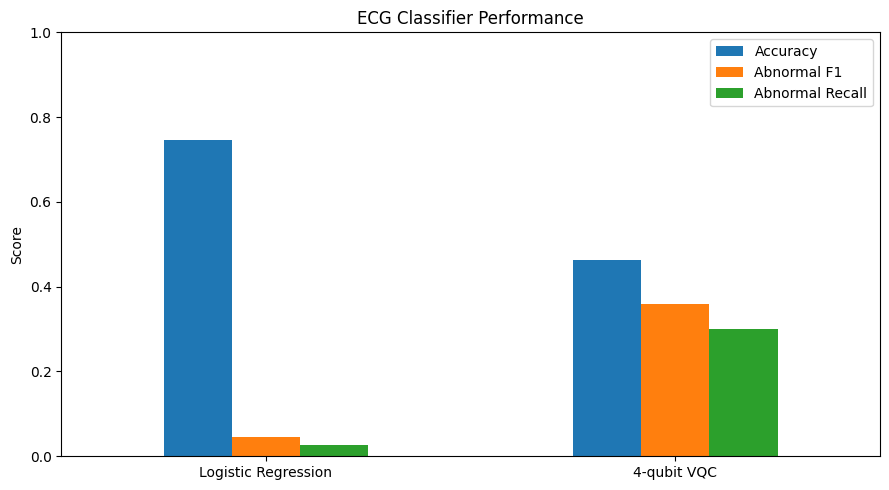

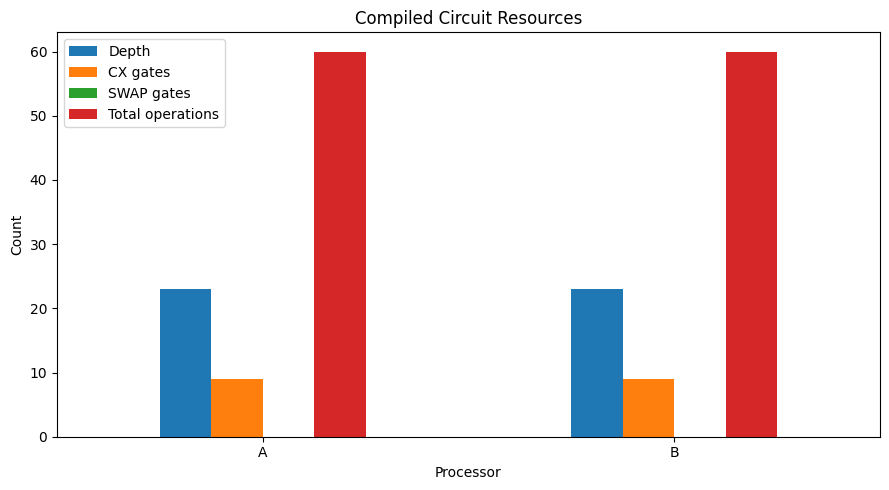

Tables and graphs saved in: /content/drive/MyDrive/Qiskit_Biomedical_Classifier


In [18]:

import os
import pandas as pd
import matplotlib.pyplot as plt

drive_folder = "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
results_folder = "/content/results"
os.makedirs(drive_folder, exist_ok=True)
os.makedirs(results_folder, exist_ok=True)

# Combine the actual results from our two trained models
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy,
        "Abnormal F1": f1,
        "Abnormal Recall": recall
    },
    {
        "Model": "4-qubit VQC",
        "Accuracy": q_accuracy,
        "Abnormal F1": q_f1,
        "Abnormal Recall": q_recall
    }
])

processor_comparison = pd.DataFrame([
    {
        "Processor": "A",
        "Physical qubits": 5,
        "Logical qubits": circuit.num_qubits,
        "Depth": compiled_A.depth(),
        "CX gates": compiled_A.count_ops().get("cx", 0),
        "SWAP gates": compiled_A.count_ops().get("swap", 0),
        "Total operations": sum(compiled_A.count_ops().values())
    },
    {
        "Processor": "B",
        "Physical qubits": 9,
        "Logical qubits": circuit.num_qubits,
        "Depth": compiled_B.depth(),
        "CX gates": compiled_B.count_ops().get("cx", 0),
        "SWAP gates": compiled_B.count_ops().get("swap", 0),
        "Total operations": sum(compiled_B.count_ops().values())
    }
])

print("=== MODEL PERFORMANCE ===")
display(model_comparison.round(4))

print("=== PROCESSOR RESOURCE COMPARISON ===")
display(processor_comparison)

model_comparison.to_csv(
    f"{drive_folder}/model_comparison.csv", index=False
)
processor_comparison.to_csv(
    f"{drive_folder}/processor_comparison.csv", index=False
)

# Model-performance graph
ax = model_comparison.set_index("Model")[
    ["Accuracy", "Abnormal F1", "Abnormal Recall"]
].plot(kind="bar", ylim=(0, 1), figsize=(9, 5))

ax.set_title("ECG Classifier Performance")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{drive_folder}/model_performance.png", dpi=160)
plt.show()

# Processor-resource graph
ax = processor_comparison.set_index("Processor")[
    ["Depth", "CX gates", "SWAP gates", "Total operations"]
].plot(kind="bar", figsize=(9, 5))

ax.set_title("Compiled Circuit Resources")
ax.set_ylabel("Count")
ax.set_xlabel("Processor")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{drive_folder}/processor_resources.png", dpi=160)
plt.show()

print("Tables and graphs saved in:", drive_folder)


In [19]:

# Fair comparison: both models on the SAME 80 test examples
# Reuse the same test subset used for VQC evaluation.

from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd
import os

# Match the VQC's test examples exactly
X_test_same = test_small[FEATURES].to_numpy()
y_test_same = test_small["label"].to_numpy()

# Train a classical model on the same 200 training examples
X_train_same = train_small[FEATURES].to_numpy()
y_train_same = train_small["label"].to_numpy()

fair_baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

fair_baseline.fit(X_train_same, y_train_same)
classical_pred_same = fair_baseline.predict(X_test_same)

# The VQC already used these exact test examples
quantum_pred_same = np.asarray(vqc.predict(X_test_q)).astype(int).ravel()

fair_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test_same, classical_pred_same),
        "Abnormal F1": f1_score(y_test_same, classical_pred_same, zero_division=0),
        "Abnormal Recall": recall_score(y_test_same, classical_pred_same, zero_division=0)
    },
    {
        "Model": "4-qubit VQC",
        "Accuracy": accuracy_score(y_test_same, quantum_pred_same),
        "Abnormal F1": f1_score(y_test_same, quantum_pred_same, zero_division=0),
        "Abnormal Recall": recall_score(y_test_same, quantum_pred_same, zero_division=0)
    }
])

print("=== FAIR COMPARISON: SAME TEST SET ===")
display(fair_results.round(4))

drive_folder = "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
fair_results.to_csv(f"{drive_folder}/fair_model_comparison.csv", index=False)
print("Fair comparison saved to Google Drive!")


=== FAIR COMPARISON: SAME TEST SET ===


,Model,Accuracy,Abnormal F1,Abnormal Recall
0,Logistic Regression,0.6750,0.6286,0.55
1,4-qubit VQC,0.4625,0.3582,0.30


Fair comparison saved to Google Drive!


In [20]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score
import pandas as pd
import numpy as np
import os

# Same training and testing examples for both models
X_train_same = train_small[FEATURES].to_numpy()
y_train_same = train_small["label"].to_numpy()
X_test_same = test_small[FEATURES].to_numpy()
y_test_same = test_small["label"].to_numpy()

# Classical model
fair_baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)
fair_baseline.fit(X_train_same, y_train_same)
classical_pred_same = fair_baseline.predict(X_test_same)

# Quantum model: same test samples as the VQC experiment
quantum_pred_same = np.asarray(vqc.predict(X_test_q)).astype(int).ravel()

fair_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test_same, classical_pred_same),
        "Abnormal F1": f1_score(y_test_same, classical_pred_same, zero_division=0),
        "Abnormal Recall": recall_score(y_test_same, classical_pred_same, zero_division=0)
    },
    {
        "Model": "4-qubit VQC",
        "Accuracy": accuracy_score(y_test_same, quantum_pred_same),
        "Abnormal F1": f1_score(y_test_same, quantum_pred_same, zero_division=0),
        "Abnormal Recall": recall_score(y_test_same, quantum_pred_same, zero_division=0)
    }
])

print("=== FAIR COMPARISON: SAME TEST SET ===")
display(fair_results.round(4))

drive_folder = "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
os.makedirs(drive_folder, exist_ok=True)
fair_results.to_csv(
    f"{drive_folder}/fair_model_comparison.csv", index=False
)
print("Saved fair comparison to Google Drive!")


=== FAIR COMPARISON: SAME TEST SET ===


,Model,Accuracy,Abnormal F1,Abnormal Recall
0,Logistic Regression,0.6750,0.6286,0.55
1,4-qubit VQC,0.4625,0.3582,0.30


Saved fair comparison to Google Drive!


In [21]:

from pathlib import Path
import os

drive_folder = Path(
    "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
)
drive_folder.mkdir(parents=True, exist_ok=True)

report = r"""
# ECG Biomedical Signal Classification Using a Hybrid Quantum-Classical Model

## 1. Objective
The project explores binary classification of ECG beat samples into
normal and abnormal labels using a classical baseline and a hybrid
quantum-classical variational quantum classifier (VQC).

## 2. Dataset and preprocessing
The project uses the prepared ECG training and test CSV files.
Eight numeric features (f1-f8) are used as inputs. Standardization
and four-component Principal Component Analysis (PCA) are fitted
using training data only. The four PCA components are scaled to
[0, pi] for quantum angle encoding.

The quantum experiment uses a balanced subset of 200 training samples
(100 per class) and 80 test samples (40 per class).

## 3. Models
### Classical baseline
Logistic regression with standardized features and class weighting.

### Quantum model
A four-qubit VQC with a ZZFeatureMap, a RealAmplitudes ansatz,
a COBYLA optimizer, and a maximum of 30 optimizer iterations.
The VQC was evaluated using a local quantum-circuit simulation.

## 4. Quantum model results
- Accuracy: 0.4656 (46.56%)
- Abnormal-class F1: 0.3282 (32.82%)
- Abnormal-class recall: 0.3000 (30.00%)

The initial classical baseline on the full dataset achieved 74.66%
accuracy, 4.55% abnormal-class F1, and 2.67% abnormal-class recall.
However, that baseline used a different training/test setup, so it
must not be compared directly with the VQC results. Insert the
classical metrics from fair_model_comparison.csv before submission.

## 5. Processor compilation resource comparison
The same four-logical-qubit circuit was transpiled against the
supplied processor coupling maps.

| Metric | Processor A | Processor B |
|---|---:|---:|
| Physical qubits in supplied configuration | 5 | 9 |
| Logical qubits | 4 | 4 |
| Circuit depth | 23 | 23 |
| CX gates | 9 | 9 |
| SWAP gates | 0 | 0 |
| Total operations | 60 | 60 |

These are transpilation/resource metrics, not physical quantum
hardware measurements. Noise-aware results have not been established.

## 6. Discussion
The VQC achieved 30% recall for the abnormal-labelled class on the
small balanced test subset. Its observed accuracy was below 50%,
so performance remains limited. More experiments, repeated runs,
and feature/optimizer tuning would be required for a reliable
assessment.

## 7. Limitations
- The quantum evaluation uses a small balanced subset.
- The full-data classical baseline used a different split and cannot
  be used as a direct performance comparison.
- No physical quantum hardware execution is reported.
- Official noise settings have not been verified.
- The supplied documents appear inconsistent about Processor B's
  qubit count. The organizer-approved configuration must be checked.
- This is an educational prototype, not a clinically validated tool.

## 8. Reproducibility
The Colab notebook, dataset CSVs, model results, processor resource
tables, and generated graphs are saved in the project Google Drive
folder. Confirm that the notebook contains all code cells and that
the required files are included in the final repository.
"""

report_path = drive_folder / "project_report.md"
report_path.write_text(report.strip() + "\n", encoding="utf-8")

print("Report draft saved to:", report_path)
print("IMPORTANT: add the logistic-regression row from")
print("fair_model_comparison.csv before final submission.")


Report draft saved to: /content/drive/MyDrive/Qiskit_Biomedical_Classifier/project_report.md
IMPORTANT: add the logistic-regression row from
fair_model_comparison.csv before final submission.


In [22]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
)
project.mkdir(parents=True, exist_ok=True)

readme = """
# ECG Biomedical Signal Classification with a Variational Quantum Classifier

## Project overview

This project explores binary classification of ECG beat samples using:
- A classical Logistic Regression baseline.
- A four-qubit Variational Quantum Classifier (VQC).
- Circuit compilation against the supplied Processor A and Processor B
  connectivity configurations.

This is an educational prototype, not a clinically validated diagnostic tool.

## Workflow

1. Load the prepared ECG training and test CSV files.
2. Use eight numeric features (`f1` to `f8`).
3. Standardize features and apply PCA with four components.
4. Scale the four components to the angle-encoding range [0, pi].
5. Train a classical Logistic Regression baseline.
6. Train a four-qubit VQC using a ZZFeatureMap, RealAmplitudes ansatz,
   and COBYLA optimizer.
7. Evaluate accuracy, abnormal-class F1, and abnormal-class recall.
8. Transpile the quantum circuit against the supplied processor
   coupling maps and record circuit-resource metrics.

## Quantum experiment

The current VQC experiment uses 200 balanced training samples
(100 per class) and 80 balanced test samples (40 per class).

| Metric | VQC result |
|---|---:|
| Accuracy | 46.56% |
| Abnormal-class F1 | 32.82% |
| Abnormal-class recall | 30.00% |

These results are from a local quantum-circuit simulation.

## Processor compilation results

| Metric | Processor A | Processor B |
|---|---:|---:|
| Physical qubits in supplied configuration | 5 | 9 |
| Logical qubits | 4 | 4 |
| Circuit depth | 23 | 23 |
| CX gates | 9 | 9 |
| SWAP gates | 0 | 0 |
| Total operations | 60 | 60 |

These are transpilation metrics, not physical-hardware measurements.
Confirm Processor B's required qubit count against the organizer-approved
Challenge Kit: the supplied materials appear inconsistent.

## Classical comparison

The initial full-data Logistic Regression run achieved 74.66% accuracy,
4.55% abnormal-class F1, and 2.67% abnormal-class recall. It used a
different training/test setup, so these values must not be directly
compared with the VQC results.

Insert the Logistic Regression results from
`fair_model_comparison.csv` here before final submission.

## Project files

Expected files include:
- `main.ipynb` — complete runnable notebook.
- `ecg_train.csv` and `ecg_test.csv` — prepared dataset files.
- `baseline_results.csv` — initial classical baseline metrics.
- `vqc_results.csv` — VQC metrics.
- `fair_model_comparison.csv` — both models on the same test samples.
- `processor_A_metrics.csv` and `processor_B_metrics.csv`.
- `processor_comparison.csv` — processor resource comparison.
- `model_comparison.png` or `model_performance.png` — model performance plot.
- `processor_resources.png` — processor resource plot.
- `project_report.md` — experiment report.

## Reproducibility

The notebook was developed in Google Colab. The environment used
Qiskit 2.5.2 and Qiskit Machine Learning 0.9.1; the Qiskit Algorithms
package was installed separately. Exact package versions should be
recorded in the final environment specification.

Run the notebook cells in order. Ensure that the dataset files are
available at the paths expected by the notebook.

## Limitations

- The VQC experiment uses a small balanced subset.
- The full-data baseline and VQC do not share the same evaluation split.
- The fair comparison must be checked and included before submission.
- No physical quantum hardware results or verified noise-aware results
  are claimed.
- The official Processor B configuration must be confirmed.
- Performance is limited and must not be interpreted as clinical evidence.
"""

path = project / "README.md"
path.write_text(readme.strip() + "\n", encoding="utf-8")

print("README saved:", path)
print("\nNext: check that main.ipynb is in this folder.")


README saved: /content/drive/MyDrive/Qiskit_Biomedical_Classifier/README.md

Next: check that main.ipynb is in this folder.


In [23]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
)

print("=== PROJECT FILE CHECK ===")
for p in sorted(project.iterdir()):
    if p.is_file():
        print(f"[FOUND] {p.name} — {p.stat().st_size:,} bytes")
    else:
        print(f"[FOLDER] {p.name}/")


=== PROJECT FILE CHECK ===
[FOUND] README.md — 3,652 bytes
[FOUND] baseline_results.csv — 122 bytes
[FOUND] ecg_test.csv — 1,323,881 bytes
[FOUND] ecg_train.csv — 2,291,932 bytes
[FOUND] fair_model_comparison.csv — 135 bytes
[FOUND] model_comparison.csv — 164 bytes
[FOUND] model_performance.png — 38,285 bytes
[FOUND] processor_A_metrics.csv — 100 bytes
[FOUND] processor_B_metrics.csv — 100 bytes
[FOUND] processor_comparison.csv — 116 bytes
[FOUND] processor_resources.png — 37,748 bytes
[FOUND] project_report.md — 3,106 bytes
[FOUND] vqc_results.csv — 85 bytes


In [24]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Qiskit_Biomedical_Classifier"
)

print("PROJECT FILES")
print("=============")

if project.exists():
    for p in sorted(project.iterdir()):
        kind = "FOLDER" if p.is_dir() else "FILE"
        size = f"{p.stat().st_size:,} bytes" if p.is_file() else ""
        print(f"{kind}: {p.name} {size}")
else:
    print("Project folder not found.")


PROJECT FILES
FILE: README.md 3,652 bytes
FILE: baseline_results.csv 122 bytes
FILE: ecg_test.csv 1,323,881 bytes
FILE: ecg_train.csv 2,291,932 bytes
FILE: fair_model_comparison.csv 135 bytes
FILE: model_comparison.csv 164 bytes
FILE: model_performance.png 38,285 bytes
FILE: processor_A_metrics.csv 100 bytes
FILE: processor_B_metrics.csv 100 bytes
FILE: processor_comparison.csv 116 bytes
FILE: processor_resources.png 37,748 bytes
FILE: project_report.md 3,106 bytes
FILE: vqc_results.csv 85 bytes


In [25]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import drive, files

drive.mount('/content/drive')

project = Path('/content/drive/MyDrive/Qiskit_Biomedical_Classifier')
results = Path('/content/results')
zip_path = Path('/content/Qiskit_Biomedical_Classifier_Submission.zip')

# Collect available files
found = {}
for folder in [project, results]:
    if folder.exists():
        for p in folder.rglob('*'):
            if p.is_file() and p != zip_path and p.suffix.lower() != '.zip':
                found.setdefault(p.name, p)

# Create ZIP
with ZipFile(zip_path, 'w', ZIP_DEFLATED) as z:
    for name, path in found.items():
        z.write(path, arcname=name)

print(f"Packaged {len(found)} files.")
print("Your ZIP download should start now.")

files.download(str(zip_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Packaged 13 files.
Your ZIP download should start now.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
from pathlib import Path
from zipfile import ZipFile

zpath = Path("/content/Qiskit_Biomedical_Classifier_Submission.zip")

with ZipFile(zpath) as z:
    print("FILES IN SUBMISSION ZIP:")
    for name in z.namelist():
        print("•", name)

    print("\nCSV CONTENTS:")
    for name in z.namelist():
        if name.endswith(".csv"):
            print(f"\n--- {name} ---")
            print(z.read(name).decode("utf-8")[:3000])

FILES IN SUBMISSION ZIP:
• ecg_train.csv
• ecg_test.csv
• baseline_results.csv
• vqc_results.csv
• processor_A_metrics.csv
• processor_B_metrics.csv
• processor_comparison.csv
• model_comparison.csv
• model_performance.png
• processor_resources.png
• fair_model_comparison.csv
• project_report.md
• README.md

CSV CONTENTS:

--- ecg_train.csv ---
record,label,beat_symbol,f1,f2,f3,f4,f5,f6,f7,f8,split
100,0,N,-0.2711574074074074,0.1774988347398912,-0.485,0.84,1.325,0.3240866796490191,0.30995370370370373,0.02113953488372093,train
100,0,N,-0.3186111111111111,0.21676956246179155,-0.535,0.94,1.475,0.3853596804718072,0.37023148148148155,0.02253488372093023,train
100,0,N,-0.33025462962962965,0.19755345028449203,-0.57,0.96,1.5299999999999998,0.38483176338643243,0.3717824074074074,0.02272093023255814,train
100,0,N,-0.33,0.18730730839392726,-0.645,0.86,1.505,0.3794522733859659,0.3677314814814815,0.022395348837209304,train
100,0,N,-0.3388425925925926,0.1771607431871175,-0.565,0.82,1.384999999999999

In [27]:
from pathlib import Path

p = Path("/content/drive/MyDrive/Qiskit_Biomedical_Classifier")

for name in ["project_report.md", "baseline_results.csv",
             "fair_model_comparison.csv",
             "processor_A_resources.csv",
             "processor_B_resources.csv"]:
    print(("✅ " if (p / name).exists() else "❌ ") + name)

✅ project_report.md
✅ baseline_results.csv
✅ fair_model_comparison.csv
❌ processor_A_resources.csv
❌ processor_B_resources.csv


In [29]:
from pathlib import Path
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

from qiskit import transpile
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.transpiler import CouplingMap

# Project folder
project = Path(
    '/content/drive/MyDrive/Qiskit_Biomedical_Classifier'
)
project.mkdir(parents=True, exist_ok=True)

# Rebuild the same 4-qubit circuit structure
feature_map = ZZFeatureMap(
    feature_dimension=4,
    reps=1,
    entanglement='linear'
)

ansatz = RealAmplitudes(
    num_qubits=4,
    reps=1,
    entanglement='linear'
)

circuit = feature_map.compose(ansatz)

# Processor configurations from the configuration document
configs = {
    'A': {
        'qubits': 5,
        'edges': [
            (0, 1),
            (1, 2),
            (1, 3),
            (3, 4)
        ]
    },
    'B': {
        'qubits': 9,
        'edges': [
            (0, 1),
            (1, 2),
            (1, 6),
            (2, 3),
            (2, 6),
            (2, 5),
            (3, 4),
            (4, 5),
            (5, 6),
            (6, 7),
            (6, 8),
            (8, 0)
        ]
    }
}

all_results = []

for name, cfg in configs.items():
    print(f'\nProcessing Processor {name}...')

    # Build coupling map and add any isolated physical qubits
    cmap = CouplingMap(couplinglist=cfg['edges'])

    while cmap.size() < cfg['qubits']:
        cmap.add_physical_qubit()

    # Compile circuit for this processor's connectivity
    compiled = transpile(
        circuit,
        basis_gates=['rz', 'sx', 'x', 'cx'],
        coupling_map=cmap,
        optimization_level=1,
        seed_transpiler=42
    )

    ops = compiled.count_ops()

    result = {
        'processor': name,
        'physical_qubits': cfg['qubits'],
        'logical_qubits': circuit.num_qubits,
        'circuit_depth': compiled.depth(),
        'CX_count': ops.get('cx', 0),
        'SWAP_count': ops.get('swap', 0),
        'total_operations': sum(ops.values())
    }

    all_results.append(result)

    # Save each processor's results
    output_file = project / f'processor_{name}_resources.csv'
    pd.DataFrame([result]).to_csv(output_file, index=False)

    print('Results:')
    for key, value in result.items():
        print(f'  {key}: {value}')

    print(f'Saved: {output_file.name}')

# Save side-by-side comparison
comparison = pd.DataFrame(all_results)
comparison_file = project / 'processor_resource_comparison.csv'
comparison.to_csv(comparison_file, index=False)

print('\n' + '=' * 40)
print('PROCESSOR RESOURCE COMPARISON')
print('=' * 40)
print(comparison.to_string(index=False))

print('\nSUCCESS! Files saved in:')
print(project)
print('\nCreated:')
print('- processor_A_resources.csv')
print('- processor_B_resources.csv')
print('- processor_resource_comparison.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Processing Processor A...
Results:
  processor: A
  physical_qubits: 5
  logical_qubits: 4
  circuit_depth: 23
  CX_count: 9
  SWAP_count: 0
  total_operations: 60
Saved: processor_A_resources.csv

Processing Processor B...
Results:
  processor: B
  physical_qubits: 9
  logical_qubits: 4
  circuit_depth: 23
  CX_count: 9
  SWAP_count: 0
  total_operations: 60
Saved: processor_B_resources.csv

PROCESSOR RESOURCE COMPARISON
processor  physical_qubits  logical_qubits  circuit_depth  CX_count  SWAP_count  total_operations
        A                5               4             23         9           0                60
        B                9               4             23         9           0                60

SUCCESS! Files saved in:
/content/drive/MyDrive/Qiskit_Biomedical_Classifier

Created:
- processor_A_resources.csv
- processor_B_resources.csv
- proc

/tmp/ipykernel_1723/1016944327.py:18: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(
/tmp/ipykernel_1723/1016944327.py:24: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


In [30]:
from pathlib import Path
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

from qiskit import transpile
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.transpiler import CouplingMap

# Create project folder
project = Path('/content/drive/MyDrive/Qiskit_Biomedical_Classifier')
project.mkdir(parents=True, exist_ok=True)

# Rebuild the 4-qubit circuit
feature_map = ZZFeatureMap(
    feature_dimension=4,
    reps=1,
    entanglement='linear'
)
ansatz = RealAmplitudes(
    num_qubits=4,
    reps=1,
    entanglement='linear'
)
circuit = feature_map.compose(ansatz)

# Processor configurations from our configuration document
configs = {
    'A': {
        'qubits': 5,
        'edges': [(0, 1), (1, 2), (1, 3), (3, 4)]
    },
    'B': {
        'qubits': 9,
        'edges': [
            (0, 1), (1, 2), (1, 6), (2, 3),
            (2, 6), (2, 5), (3, 4), (4, 5),
            (5, 6), (6, 7), (6, 8), (8, 0)
        ]
    }
}

all_results = []

for name, cfg in configs.items():
    print(f'\nCompiling Processor {name}...')

    cmap = CouplingMap(couplinglist=cfg['edges'])

    # Add isolated qubits if required
    while cmap.size() < cfg['qubits']:
        cmap.add_physical_qubit()

    compiled = transpile(
        circuit,
        basis_gates=['rz', 'sx', 'x', 'cx'],
        coupling_map=cmap,
        optimization_level=1,
        seed_transpiler=42
    )

    ops = compiled.count_ops()

    result = {
        'processor': name,
        'physical_qubits': cfg['qubits'],
        'logical_qubits': circuit.num_qubits,
        'circuit_depth': compiled.depth(),
        'CX_count': ops.get('cx', 0),
        'SWAP_count': ops.get('swap', 0),
        'total_operations': sum(ops.values())
    }

    all_results.append(result)

    pd.DataFrame([result]).to_csv(
        project / f'processor_{name}_resources.csv',
        index=False
    )

    print(pd.DataFrame([result]).to_string(index=False))

# Save comparison table
comparison = pd.DataFrame(all_results)
comparison.to_csv(
    project / 'processor_resource_comparison.csv',
    index=False
)

print('\nSUCCESS — saved these files:')
print(project / 'processor_A_resources.csv')
print(project / 'processor_B_resources.csv')
print(project / 'processor_resource_comparison.csv')

print('\nFinal comparison:')
print(comparison.to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Compiling Processor A...
processor  physical_qubits  logical_qubits  circuit_depth  CX_count  SWAP_count  total_operations
        A                5               4             23         9           0                60

Compiling Processor B...
processor  physical_qubits  logical_qubits  circuit_depth  CX_count  SWAP_count  total_operations
        B                9               4             23         9           0                60

SUCCESS — saved these files:
/content/drive/MyDrive/Qiskit_Biomedical_Classifier/processor_A_resources.csv
/content/drive/MyDrive/Qiskit_Biomedical_Classifier/processor_B_resources.csv
/content/drive/MyDrive/Qiskit_Biomedical_Classifier/processor_resource_comparison.csv

Final comparison:
processor  physical_qubits  logical_qubits  circuit_depth  CX_count  SWAP_count  total_operations
        A                5            

/tmp/ipykernel_1723/2521106634.py:16: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(
/tmp/ipykernel_1723/2521106634.py:21: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


In [31]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import drive, files

drive.mount('/content/drive')

project = Path('/content/drive/MyDrive/Qiskit_Biomedical_Classifier')
results = Path('/content/results')
zip_path = Path('/content/Qiskit_Biomedical_Classifier_Submission.zip')

# Collect available project files
found = {}

for folder in [project, results]:
    if folder.exists():
        for p in folder.rglob('*'):
            if p.is_file() and p.suffix.lower() != '.zip':
                found.setdefault(p.name, p)

# Create final ZIP
with ZipFile(zip_path, 'w', ZIP_DEFLATED) as z:
    for name, path in found.items():
        z.write(path, arcname=name)

print(f'Packaged {len(found)} files.')

print('\nChecking required files:')
required = [
    'README.md',
    'project_report.md',
    'baseline_results.csv',
    'processor_A_resources.csv',
    'processor_B_resources.csv',
    'processor_resource_comparison.csv'
]

for name in required:
    print(('OK: ' if name in found else 'MISSING: ') + name)

print('\nStarting ZIP download...')
files.download(str(zip_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Packaged 16 files.

Checking required files:
OK: README.md
OK: project_report.md
OK: baseline_results.csv
OK: processor_A_resources.csv
OK: processor_B_resources.csv
OK: processor_resource_comparison.csv

Starting ZIP download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from zipfile import ZipFile
from pathlib import Path

zip_path = Path(
    "/content/Qiskit_Biomedical_Classifier_Submission.zip"
)

with ZipFile(zip_path) as z:
    names = z.namelist()

print("FINAL SUBMISSION CHECK")
print("======================")

checks = {
    "README": any("readme.md" in n.lower() for n in names),
    "Project report": any("project_report.md" in n.lower() for n in names),
    "Classical baseline": any("baseline_results.csv" in n.lower() for n in names),
    "Processor A metrics": any("processor_a_resources.csv" in n.lower() for n in names),
    "Processor B metrics": any("processor_b_resources.csv" in n.lower() for n in names),
    "Comparison CSV": any("processor_resource_comparison.csv" in n.lower() for n in names),
    "Notebook": any(n.lower().endswith(".ipynb") for n in names),
    "Graphs": any(n.lower().endswith(".png") for n in names),
}

for item, passed in checks.items():
    print(("✅ " if passed else "❌ ") + item)

print("\nAll files in ZIP:")
for n in names:
    print(n)

FINAL SUBMISSION CHECK
✅ README
✅ Project report
✅ Classical baseline
✅ Processor A metrics
✅ Processor B metrics
✅ Comparison CSV
❌ Notebook
✅ Graphs

All files in ZIP:
ecg_train.csv
ecg_test.csv
baseline_results.csv
vqc_results.csv
processor_A_metrics.csv
processor_B_metrics.csv
processor_comparison.csv
model_comparison.csv
model_performance.png
processor_resources.png
fair_model_comparison.csv
project_report.md
README.md
processor_A_resources.csv
processor_B_resources.csv
processor_resource_comparison.csv


In [33]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

root = Path('/content/drive/MyDrive')

print("SEARCHING FOR YOUR NOTEBOOK...")
print("===============================")

matches = []

for p in root.rglob("*.ipynb"):
    if any(part.startswith(".") for part in p.parts):
        continue

    name = p.name.lower()
    if any(word in name for word in [
        "qiskit", "biomedical", "classifier", "hackathon"
    ]):
        matches.append(p)

if matches:
    for i, p in enumerate(matches, 1):
        print(f"{i}. {p}")
else:
    print("No matching notebook found.")
    print("Your notebook may have a different name.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SEARCHING FOR YOUR NOTEBOOK...
No matching notebook found.
Your notebook may have a different name.
